(AQUASENSE PROJECT) A MACHINE LEARNING WATER POTABILITY ASSESMENT MODEL  
BY
  Odoi Stephen  
Reg: 2026/HD05/22777U



In [ ]:
#LIBRARIES/PACKAGES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score, precision_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, recall_score, precision_score
from sklearn.metrics import (
    roc_curve,
    recall_score,
    precision_score,
    confusion_matrix,
    f1_score,
    accuracy_score

)
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
import os
import sys
import joblib
import sklearn



In [ ]:


# Collecting the data from my drive
from google.colab import drive

# Mount Google Drive to the standard mount point
drive.mount('/content/drive')

# Load the CSV file into a table called water_data
water_data = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/water_potability.csv")

# Show the size of the dataset
print("Number of rows:", water_data.shape[0])
print("Number of columns:", water_data.shape[1])

# Show the first five records
display(water_data.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Number of rows: 3276
Number of columns: 10


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [ ]:

water_data.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


CHECKING FOR MISSING VALUES


In [ ]:
# Counting missing values in each column
missing_counts = water_data.isna().sum()

#  percentage missing in each column
missing_percentages = water_data.isna().mean() * 100

# Putting the results into a table
missing_summary = pd.DataFrame({
    "Number missing": missing_counts,
    "Percentage missing (%)": missing_percentages
})

# Display the table
display(missing_summary.round(2))

# Count all missing cells in the dataset
print("Total missing values:", missing_counts.sum())

,Number missing,Percentage missing (%)
ph,491,14.99
Hardness,0,0.00
Solids,0,0.00
Chloramines,0,0.00
Sulfate,781,23.84
Conductivity,0,0.00
Organic_carbon,0,0.00
Trihalomethanes,162,4.95
Turbidity,0,0.00
Potability,0,0.00


Total missing values: 1434


Finding out the number of records that  are incomplete

In [ ]:
# Checking  each row for at least one missing value
has_missing = water_data.isna().any(axis=1)

# Counting incomplete and complete rows
rows_with_missing = has_missing.sum()
total_rows = len(water_data)
complete_rows = total_rows - rows_with_missing

# Displaying the results
print("Total number of records:", total_rows)
print("Records with at least one missing value:", rows_with_missing)
print("Records with no missing values:", complete_rows)

print(
    "Percentage of records with missing values:",
    round(rows_with_missing / total_rows * 100, 2),
    "%"
)

Total number of records: 3276
Records with at least one missing value: 1265
Records with no missing values: 2011
Percentage of records with missing values: 38.61 %


ExPLORING THE OUT COME CATEGORIES

In [ ]:
# Counting  the records in each Potability category
class_counts = water_data["Potability"].value_counts(
    dropna=False
).sort_index()

# Calculating the percentage in each category
class_percentages = class_counts / len(water_data) * 100

# Putting the counts and percentages into a table
class_summary = pd.DataFrame({
    "Number of records": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

# Displaying the results
display(class_summary)

,Number of records,Percentage (%)
Potability,,
0,1998,60.99
1,1278,39.01


DIVIDING THE DATA IN TO TRAINING AND TESTING DATA SET


1.   80% TRAINING MODELS
2.   20% EVALUATING SELECTED MODEL



In [ ]:


#EXCLUDING OUT COME COLUMN FROM PREDICTORS
X = water_data.drop(columns=["Potability"])

# y contains the outcome we want to predict
y = water_data["Potability"]

# DividING  X and y into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the number of records in each set
print("Total records:", len(water_data))
print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Number of predictors:", X_train.shape[1])

# Check the outcome categories in each set
print("\nTraining-set label counts:")
print(y_train.value_counts().sort_index())

print("\nTest-set label counts:")
print(y_test.value_counts().sort_index())

Total records: 3276
Training records: 2620
Test records: 656
Number of predictors: 9

Training-set label counts:
Potability
0    1598
1    1022
Name: count, dtype: int64

Test-set label counts:
Potability
0    400
1    256
Name: count, dtype: int64


DATA PROCESSING

*   FILLING THE MISSING VALUES WITH MEDIAN
*   SCALING THE PREDICTOR VALUES



In [ ]:
# Importing  the tools for preparing our measurements
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [ ]:

# the preprocessing steps
preprocessing_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Examine missing values and medians in the training data
training_missing = X_train.isna().sum()
columns_with_missing = training_missing[training_missing > 0].index

training_preview = pd.DataFrame({
    "Missing values in training": training_missing.loc[columns_with_missing],
    "Training median": X_train[columns_with_missing].median()
})

display(training_preview.round(2))



,Missing values in training,Training median
ph,387,7.04
Sulfate,625,333.07
Trihalomethanes,134,66.57


DEVELOPING THE FIRST MODEL: LOGISTIC REGRESSION

In [ ]:

# Combine the preprocessing steps with logistic regression
logistic_model = Pipeline(steps=[
    ("preprocessing", preprocessing_pipeline),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Define the measures we want to calculate
scoring = {
    "accuracy": "accuracy",

    # Label 0 is non-potable
    "recall_0": make_scorer(
        recall_score, pos_label=0, zero_division=0
    ),
    "precision_0": make_scorer(
        precision_score, pos_label=0, zero_division=0
    ),

    # Label 1 is potable
    "recall_1": make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),

    "roc_auc": "roc_auc"
}

# Create five folds with similar label proportions
folds = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the pipeline using the training data only
cv_scores = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=folds,
    scoring=scoring,
    error_score="raise"
)

# Summarise the average results
logistic_results = pd.DataFrame({
    "Performance measure": [
        "Accuracy",
        "Recall for non-potable (0)",
        "Precision for non-potable (0)",
        "Recall for potable (1)",
        "ROC-AUC"
    ],
    "Average score": [
        cv_scores["test_accuracy"].mean(),
        cv_scores["test_recall_0"].mean(),
        cv_scores["test_precision_0"].mean(),
        cv_scores["test_recall_1"].mean(),
        cv_scores["test_roc_auc"].mean()
    ]
})

display(logistic_results.round(3))

,Performance measure,Average score
0,Accuracy,0.610
1,Recall for non-potable (0),1.000
2,Precision for non-potable (0),0.610
3,Recall for potable (1),0.000
4,ROC-AUC,0.477


BUILDING ANOTHER MODEL FOR COMPARISON: RANDOM FOREST MODEL

In [ ]:

# Combining preprocessing with the random forest
forest_model = Pipeline(steps=[
    ("preprocessing", preprocessing_pipeline),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Evaluating the random forest on the same five training folds
forest_cv_scores = cross_validate(
    forest_model,
    X_train,
    y_train,
    cv=folds,
    scoring=scoring,
    error_score="raise"
)

# Summarising the random forest results
forest_results = pd.DataFrame({
    "Performance measure": [
        "Accuracy",
        "Recall for non-potable (0)",
        "Precision for non-potable (0)",
        "Recall for potable (1)",
        "ROC-AUC"
    ],
    "Average score": [
        forest_cv_scores["test_accuracy"].mean(),
        forest_cv_scores["test_recall_0"].mean(),
        forest_cv_scores["test_precision_0"].mean(),
        forest_cv_scores["test_recall_1"].mean(),
        forest_cv_scores["test_roc_auc"].mean()
    ]
})

# Putting the two models side by side
comparison = logistic_results.merge(
    forest_results,
    on="Performance measure",
    suffixes=(" - logistic", " - random forest")
)

display(comparison.round(3))

,Performance measure,Average score - logistic,Average score - random forest
0,Accuracy,0.610,0.669
1,Recall for non-potable (0),1.000,0.875
2,Precision for non-potable (0),0.610,0.677
3,Recall for potable (1),0.000,0.347
4,ROC-AUC,0.477,0.682


BUILDING ANOTHER MODEL: GRADIENT BOOSTING MODEL FOR COMPARISON

In [ ]:

# Combining preprocessing with gradient boosting
gradient_model = Pipeline(steps=[
    ("preprocessing", preprocessing_pipeline),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Evaluating it using the same five training folds
gradient_cv_scores = cross_validate(
    gradient_model,
    X_train,
    y_train,
    cv=folds,
    scoring=scoring,
    error_score="raise"
)

# Summarising the gradient boosting results
gradient_results = pd.DataFrame({
    "Performance measure": [
        "Accuracy",
        "Recall for non-potable (0)",
        "Precision for non-potable (0)",
        "Recall for potable (1)",
        "ROC-AUC"
    ],
    "Average score - gradient boosting": [
        gradient_cv_scores["test_accuracy"].mean(),
        gradient_cv_scores["test_recall_0"].mean(),
        gradient_cv_scores["test_precision_0"].mean(),
        gradient_cv_scores["test_recall_1"].mean(),
        gradient_cv_scores["test_roc_auc"].mean()
    ]
})

# Adding gradient boosting to the existing comparison table
comparison_three = comparison.merge(
    gradient_results,
    on="Performance measure"
)

display(comparison_three.round(3))

,Performance measure,Average score - logistic,Average score - random forest,Average score - gradient boosting
0,Accuracy,0.610,0.669,0.642
1,Recall for non-potable (0),1.000,0.875,0.889
2,Precision for non-potable (0),0.610,0.677,0.651
3,Recall for potable (1),0.000,0.347,0.255
4,ROC-AUC,0.477,0.682,0.641


RANDOM FOREST IS THE BEST OUT OF THE THREE.
HOWEVER WE AR GOING TO FIRST EXAMIME IT:

*  with the following thresholds;
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]



In [ ]:

# Checking if the training labels are the expected categories
assert set(y_train.unique()) == {0, 1}, "Unexpected outcome labels."

# Get one cross-validated prediction for each training record
rf_oof_probabilities = cross_val_predict(
    forest_model,
    X_train,
    y_train,
    cv=folds,
    method="predict_proba"
)

# Column 0 contains the model's score for label 0: non-potable
rf_oof_nonpotable = rf_oof_probabilities[:, 0]

# Thresholds to examine
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_rows = []

for threshold in thresholds:
    # Predict 0 when the non-potable score reaches the threshold
    predictions = np.where(rf_oof_nonpotable >= threshold, 0, 1)

    # Rows are recorded labels; columns are predicted labels
    matrix = confusion_matrix(y_train, predictions, labels=[0, 1])

    threshold_rows.append({
        "Threshold": threshold,
        "Non-potable recall (%)": 100 * recall_score(
            y_train, predictions, pos_label=0
        ),
        "Potable recall (%)": 100 * recall_score(
            y_train, predictions, pos_label=1
        ),
        "Non-potable precision (%)": 100 * precision_score(
            y_train, predictions, pos_label=0, zero_division=0
        ),
        "Non-potable missed": matrix[0, 1],
        "Potable flagged non-potable": matrix[1, 0]
    })

# Display the results
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(2))

,Threshold,Non-potable recall (%),Potable recall (%),Non-potable precision (%),Non-potable missed,Potable flagged non-potable
0,0.2,99.75,1.76,61.35,4,1004
1,0.3,99.19,6.36,62.35,13,957
2,0.4,97.18,16.14,64.44,45,857
3,0.5,87.55,34.74,67.72,199,667
4,0.6,64.83,61.15,72.30,562,397
5,0.7,32.04,84.25,76.08,1086,161


COMPARING THE RANDOM FOREST AND GRADIENT BOOST MODELS AT A SIMILAR RECALL LEVEL

*   when we identify at least 95% of non-potable records, how many potable records does each model correctly recognise?




In [ ]:


# Illustrative target for non-potable recall
target_recall = 0.95

# Obtain cross-validated scores for gradient boosting
gradient_oof_probabilities = cross_val_predict(
    gradient_model,
    X_train,
    y_train,
    cv=folds,
    method="predict_proba"
)

# Column 0 is the score for label 0: non-potable
gradient_oof_nonpotable = gradient_oof_probabilities[:, 0]

# Use the random forest scores calculated in the previous step
model_scores = {
    "Random forest": rf_oof_nonpotable,
    "Gradient boosting": gradient_oof_nonpotable
}

comparison_rows = []
thresholds_by_model = {}

for model_name, scores in model_scores.items():

    # Examine possible thresholds, treating label 0 as the class of interest
    false_positive_rates, recalls, possible_thresholds = roc_curve(
        y_train,
        scores,
        pos_label=0,
        drop_intermediate=False
    )

    # Find the highest threshold that achieves at least 95% recall
    eligible_index = np.flatnonzero(recalls >= target_recall)[0]
    selected_threshold = possible_thresholds[eligible_index]

    # Keep the full-precision threshold for later use
    thresholds_by_model[model_name] = selected_threshold

    # Apply the threshold to the cross-validated scores
    predictions = np.where(scores >= selected_threshold, 0, 1)

    # Rows are recorded labels; columns are predictions
    matrix = confusion_matrix(y_train, predictions, labels=[0, 1])

    comparison_rows.append({
        "Model": model_name,
        "Threshold": selected_threshold,
        "Non-potable recall (%)": 100 * recall_score(
            y_train, predictions, pos_label=0
        ),
        "Potable recall (%)": 100 * recall_score(
            y_train, predictions, pos_label=1
        ),
        "Non-potable precision (%)": 100 * precision_score(
            y_train, predictions, pos_label=0, zero_division=0
        ),
        "Non-potable missed": matrix[0, 1],
        "Potable flagged non-potable": matrix[1, 0]
    })

# Display the comparison
matched_comparison = pd.DataFrame(comparison_rows)
display(matched_comparison.round(3))

,Model,Threshold,Non-potable recall (%),Potable recall (%),Non-potable precision (%),Non-potable missed,Potable flagged non-potable
0,Random forest,0.435,95.369,21.331,65.464,74,804
1,Gradient boosting,0.431,95.056,17.906,64.419,79,839


RANDOM FOREST PROOVES THE BEST,

*  Evaluating the model on the test set
*   



In [ ]:

# Retrieving the full-precision threshold selected from training data
selected_threshold = float(thresholds_by_model["Random forest"])

# Checking whether measurements and outcome labels are aligned
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

# Making a fresh copy and training it on all training records
final_model = clone(forest_model)
final_model.fit(X_train, y_train)

# Finding the probability column corresponding to label 0
nonpotable_column = list(final_model.classes_).index(0)

# Obtain the model's scores for non-potable on the test set
test_scores_nonpotable = final_model.predict_proba(X_test)[
    :, nonpotable_column
]

# Applying our selected threshold
y_test_pred = np.where(
    test_scores_nonpotable >= selected_threshold,
    0,
    1
)

# Calculating test-set performance
test_results = pd.DataFrame({
    "Performance measure": [
        "Accuracy",
        "Recall for non-potable (0)",
        "Recall for potable (1)",
        "Precision for non-potable (0)",
        "F1-score for non-potable (0)",
        "ROC-AUC"
    ],
    "Test score": [
        accuracy_score(y_test, y_test_pred),

        recall_score(
            y_test, y_test_pred, pos_label=0, zero_division=0
        ),

        recall_score(
            y_test, y_test_pred, pos_label=1, zero_division=0
        ),

        precision_score(
            y_test, y_test_pred, pos_label=0, zero_division=0
        ),

        f1_score(
            y_test, y_test_pred, pos_label=0, zero_division=0
        ),

        roc_auc_score(
            (y_test == 0).astype(int),
            test_scores_nonpotable
        )
    ]
})

print("Number of test records:", len(y_test))
print("Selected threshold for label 0:", selected_threshold)

print("\nTest-set performance:")
display(test_results.round(3))

# Creating a confusion matrix
test_matrix = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

test_confusion_table = pd.DataFrame(
    test_matrix,
    index=[
        "Recorded non-potable (0)",
        "Recorded potable (1)"
    ],
    columns=[
        "Predicted non-potable (0)",
        "Predicted potable (1)"
    ]
)

print("\nTest-set confusion matrix:")
display(test_confusion_table)

Number of test records: 656
Selected threshold for label 0: 0.435

Test-set performance:


,Performance measure,Test score
0,Accuracy,0.663
1,Recall for non-potable (0),0.960
2,Recall for potable (1),0.199
3,Precision for non-potable (0),0.652
4,F1-score for non-potable (0),0.777
5,ROC-AUC,0.653



Test-set confusion matrix:


,Predicted non-potable (0),Predicted potable (1)
Recorded non-potable (0),384,16
Recorded potable (1),205,51


Examining the measurements the forest used

,Measurement,Relative importance
0,ph,0.1293
1,Sulfate,0.1276
2,Hardness,0.1231
3,Chloramines,0.1157
4,Solids,0.1125
5,Conductivity,0.1010
6,Turbidity,0.0987
7,Organic_carbon,0.0963
8,Trihalomethanes,0.0958


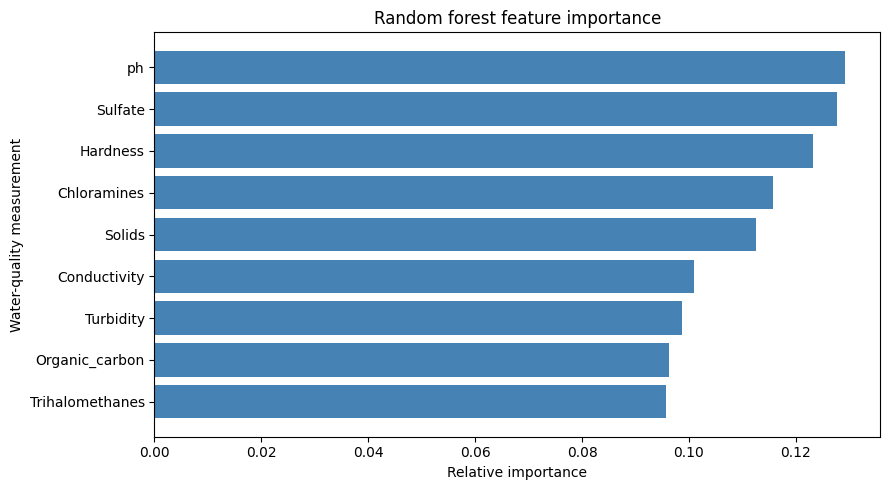

In [ ]:


# Get the trained random forest from the full pipeline
trained_forest = final_model.named_steps["classifier"]

# Get the importance assigned to each measurement
importance_values = trained_forest.feature_importances_

# Check that the importance values match the predictor columns
assert len(importance_values) == len(X_train.columns)

# Create and sort the results table
feature_importance = pd.DataFrame({
    "Measurement": X_train.columns,
    "Relative importance": importance_values
}).sort_values(
    by="Relative importance",
    ascending=False
).reset_index(drop=True)

# Display the table
display(feature_importance.round(4))

# Arrange the measurements for a horizontal bar chart
plot_data = feature_importance.sort_values(
    by="Relative importance",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    plot_data["Measurement"],
    plot_data["Relative importance"],
    color="steelblue"
)

plt.xlabel("Relative importance")
plt.ylabel("Water-quality measurement")
plt.title("Random forest feature importance")
plt.tight_layout()
plt.show()

Drawing the test-set ROC curve

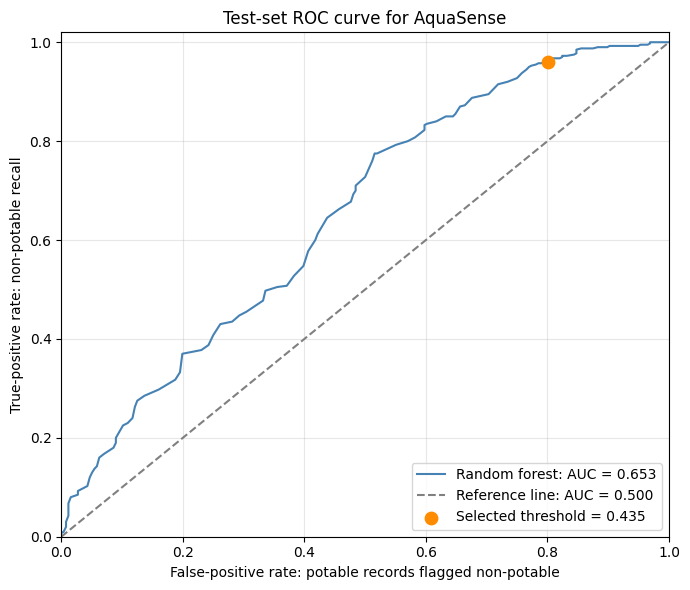

Test ROC-AUC: 0.653
Non-potable recall at selected threshold: 96.0 %
False-positive rate at selected threshold: 80.1 %


In [ ]:

# Calculate the ROC curve, treating non-potable (0) as the class of interest
false_positive_rates, true_positive_rates, roc_thresholds = roc_curve(
    y_test,
    test_scores_nonpotable,
    pos_label=0,
    drop_intermediate=False
)

# Calculate test ROC-AUC using scores for non-potable
test_roc_auc = roc_auc_score(
    (y_test == 0).astype(int),
    test_scores_nonpotable
)

# Calculate the position of our selected threshold
nonpotable_recall = recall_score(
    y_test,
    y_test_pred,
    pos_label=0
)

potable_recall = recall_score(
    y_test,
    y_test_pred,
    pos_label=1
)

false_positive_at_threshold = 1 - potable_recall

# Draw the ROC curve
plt.figure(figsize=(7, 6))

plt.plot(
    false_positive_rates,
    true_positive_rates,
    color="steelblue",
    label=f"Random forest: AUC = {test_roc_auc:.3f}"
)

# Add a reference line for a model with no discrimination
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Reference line: AUC = 0.500"
)

# Mark the threshold chosen from training data
plt.scatter(
    false_positive_at_threshold,
    nonpotable_recall,
    color="darkorange",
    s=80,
    zorder=3,
    label=f"Selected threshold = {selected_threshold:.3f}"
)

plt.xlabel("False-positive rate: potable records flagged non-potable")
plt.ylabel("True-positive rate: non-potable recall")
plt.title("Test-set ROC curve for AquaSense")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Test ROC-AUC:", round(test_roc_auc, 3))
print("Non-potable recall at selected threshold:",
      round(nonpotable_recall * 100, 1), "%")
print("False-positive rate at selected threshold:",
      round(false_positive_at_threshold * 100, 1), "%")

saving the trained model

In [ ]:
# Choose where to save the file in Google Drive
save_folder = "/content/drive/MyDrive/AquaSense"
save_path = os.path.join(
    save_folder,
    "AquaSense_random_forest_v1.joblib"
)

# Set to True if you want to overwrite the existing saved model file
overwrite = True

# Check that the folder exists
if not os.path.isdir(save_folder):
    raise FileNotFoundError(
        "AquaSense folder not found. Check the folder path and Google Drive connection."
    )

# Avoid overwriting unless explicitly enabled
if os.path.exists(save_path) and not overwrite:
    raise FileExistsError(
        "The file already exists. Change v1 to v2 in the filename, or set overwrite = True to replace it."
    )

# Put everything needed together in one bundle
model_bundle = {
    "model": final_model,
    "threshold_nonpotable": float(selected_threshold),
    "feature_names": X_train.columns.tolist(),
    "class_meaning": {
        0: "Dataset label: non-potable",
        1: "Dataset label: potable"
    },
    "sklearn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "joblib_version": joblib.__version__,
    "python_version": sys.version.split()[0]
}

# Save the bundle
joblib.dump(model_bundle, save_path)

print("Model bundle saved to:", save_path)
print("Saved non-potable threshold:", model_bundle["threshold_nonpotable"])

# Reload the saved bundle and check its predictions
loaded_bundle = joblib.load(save_path)
loaded_model = loaded_bundle["model"]

# Find the probability column for label 0
class_0_column = list(loaded_model.classes_).index(0)

# Calculate scores using the saved model
loaded_scores = loaded_model.predict_proba(
    X_test.loc[:, loaded_bundle["feature_names"]]
)[:, class_0_column]

# Apply the saved threshold
loaded_predictions = np.where(
    loaded_scores >= loaded_bundle["threshold_nonpotable"],
    0,
    1
)

# Check whether these match our earlier predictions
predictions_match = np.array_equal(
    loaded_predictions,
    np.asarray(y_test_pred)
)

print("Reloaded predictions match previous test predictions:", predictions_match)

Model bundle saved to: /content/drive/MyDrive/AquaSense/AquaSense_random_forest_v1.joblib
Saved non-potable threshold: 0.435
Reloaded predictions match previous test predictions: True


making a prediction for one water sample

In [ ]:
# Select the first record from the test set
sample = X_test.iloc[[0]][loaded_bundle["feature_names"]]

print("Water measurements for the selected record:")
display(sample)

# Find the model's score for label 0: non-potable
class_0_column = list(loaded_model.classes_).index(0)

nonpotable_score = loaded_model.predict_proba(sample)[0, class_0_column]

# Retrieve our saved decision threshold
threshold = loaded_bundle["threshold_nonpotable"]

# Apply the threshold to make a prediction
if nonpotable_score >= threshold:
    predicted_label = 0
else:
    predicted_label = 1

# Get the recorded label for this same record
recorded_label = int(y_test.iloc[0])

# Make the labels easier to understand
label_names = {
    0: "Non-potable (0)",
    1: "Potable (1)"
}

print("Dataset row index:", sample.index[0])
print(f"Model score for non-potable: {nonpotable_score:.4f}")
print(f"Decision threshold: {threshold:.4f}")
print("Predicted label:", label_names[predicted_label])
print("Recorded label:", label_names[recorded_label])

Water measurements for the selected record:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
664,NaN,188.743562,19037.462638,6.034236,NaN,388.065857,15.149068,78.499418,2.723651


Dataset row index: 664
Model score for non-potable: 0.7400
Decision threshold: 0.4350
Predicted label: Non-potable (0)
Recorded label: Potable (1)
